In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load the cleaned dataset again
file_path = "/content/drive/MyDrive/Dataset/aqi_selected_cities_cleaned.csv"
data = pd.read_csv(file_path)
# Convert 'timestamp' to datetime
data['timestamp'] = pd.to_datetime(data['timestamp'], errors='coerce')

In [ ]:
data.isnull().sum().sort_values(ascending=False)

,0
timestamp,0
city,0
aqi,0
wind_speed,0
humidity,0
temperature,0
pm25,0
pm10,0
o3,0
no2,0


In [ ]:
summary_stats = data.describe(include='all').drop(['timestamp','city'], axis=1)
summary_stats_cleaned = summary_stats.drop(index=["unique", "top", "freq"])
display(summary_stats_cleaned)


,aqi,wind_speed,humidity,temperature,pm25,pm10,o3,no2,so2,co
count,18298.000000,18298.000000,18298.000000,18298.000000,18298.000000,18298.000000,18298.000000,18298.000000,18298.000000,18298.000000
mean,86.922997,10.599656,75.584599,25.378254,30.105793,44.778719,20.398131,22.598251,15.419346,1.323686
min,9.000000,0.000000,25.000000,10.600000,0.600000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,56.000000,6.100000,66.000000,22.200000,12.000000,7.500000,0.000000,2.500000,0.900000,0.500000
50%,76.000000,9.700000,78.000000,26.100000,22.400000,31.700000,12.200000,11.400000,3.000000,1.100000
75%,111.000000,14.500000,88.000000,28.900000,39.600000,71.600000,42.300000,17.400000,15.200000,2.100000
max,284.000000,47.800000,100.000000,38.900000,209.200000,298.000000,205.600000,215.800000,92.400000,99.900000
std,44.375418,5.706580,14.552488,5.140277,26.358765,46.014115,23.272091,31.357780,23.440372,1.888878


/tmp/ipython-input-5-2141116409.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='city', y='aqi', palette='coolwarm')


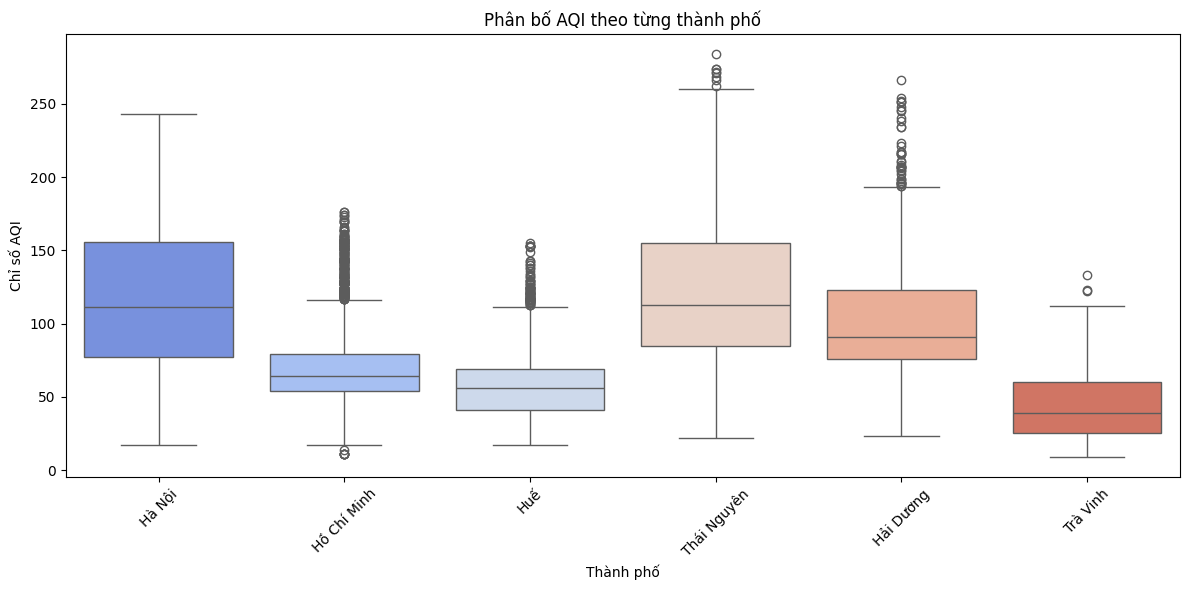

In [ ]:
# Boxplot of AQI by city
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='city', y='aqi', palette='coolwarm')
plt.title('Phân bố AQI theo từng thành phố')
plt.xlabel('Thành phố')
plt.ylabel('Chỉ số AQI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

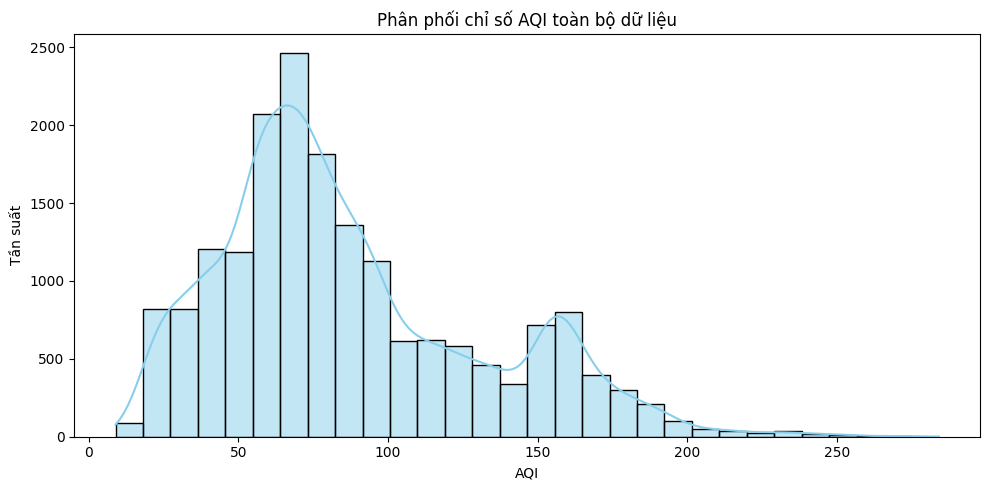

In [ ]:
# Histogram of AQI
plt.figure(figsize=(10, 5))
sns.histplot(data['aqi'], bins=30, kde=True, color='skyblue')
plt.title('Phân phối chỉ số AQI toàn bộ dữ liệu')
plt.xlabel('AQI')
plt.ylabel('Tần suất')
plt.tight_layout()
plt.show()

/tmp/ipython-input-9-2219847763.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='city', y='temperature', palette='coolwarm')


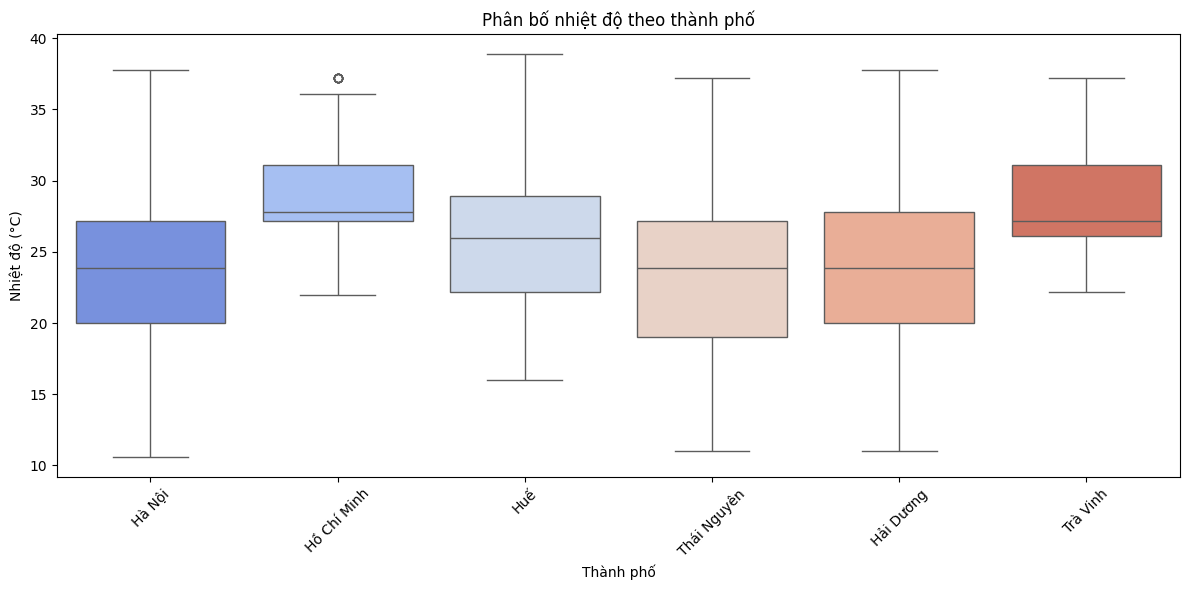

In [ ]:
# Boxplot of temperature by city
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='city', y='temperature', palette='coolwarm')
plt.title('Phân bố nhiệt độ theo thành phố')
plt.xlabel('Thành phố')
plt.ylabel('Nhiệt độ (°C)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**4.2 Phân tích xu hướng theo thời gian**

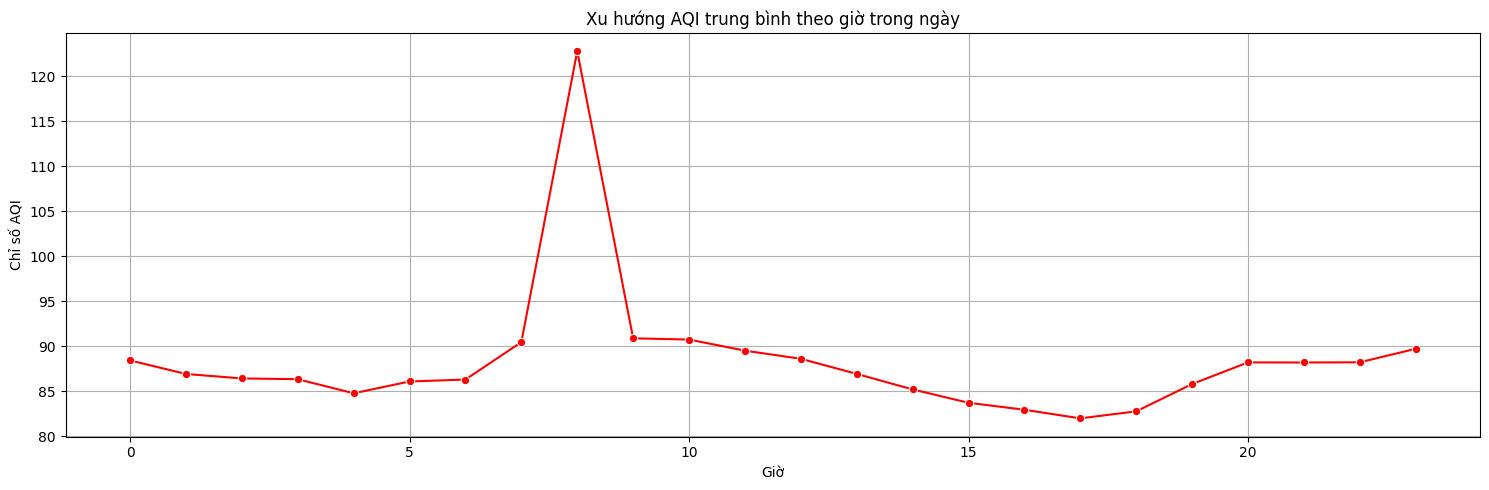

In [ ]:
# Tạo cột ngày, giờ, tháng
data['date'] = pd.to_datetime(data['timestamp']).dt.date
data['hour'] = pd.to_datetime(data['timestamp']).dt.hour
data['month'] = pd.to_datetime(data['timestamp']).dt.month

# Tính AQI trung bình theo giờ
aqi_by_hour = data.groupby("hour")["aqi"].mean().reset_index()
# Vẽ biểu đồ xu hướng AQI theo giờ
plt.figure(figsize=(15, 5))
sns.lineplot(data=aqi_by_hour, x="hour", y="aqi", marker='o', color = "red")
plt.title("Xu hướng AQI trung bình theo giờ trong ngày")
plt.xlabel("Giờ")
plt.ylabel("Chỉ số AQI")
plt.grid(True)
plt.tight_layout()
plt.show()

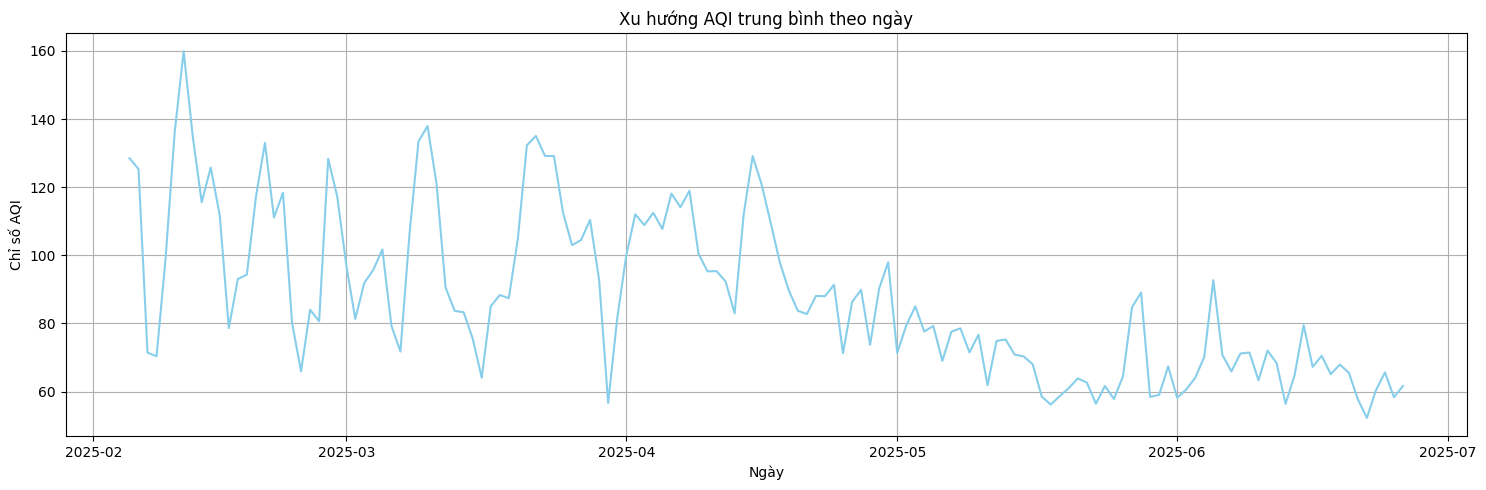

In [ ]:
# Tính AQI trung bình theo ngày
aqi_by_date = data.groupby("date")["aqi"].mean().reset_index()
# Vẽ biểu đồ xu hướng AQI theo ngày
plt.figure(figsize=(15, 5))
sns.lineplot(data=aqi_by_date, x="date", y="aqi", color = "skyblue")
plt.title("Xu hướng AQI trung bình theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Chỉ số AQI")
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipython-input-12-4259875046.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=aqi_by_month, x="month", y="aqi", palette="coolwarm")


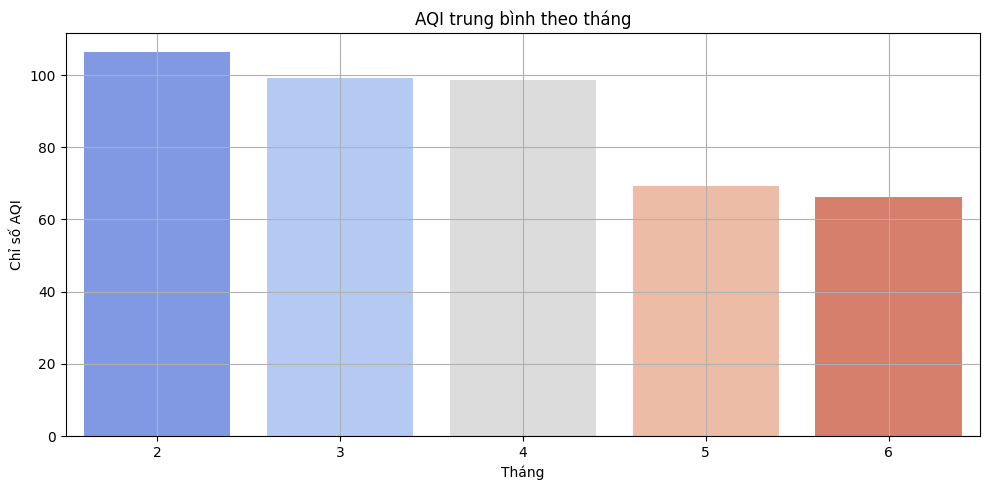

In [ ]:
# Tính AQI trung bình theo tháng
aqi_by_month = data.groupby("month")["aqi"].mean().reset_index()
# Vẽ biểu đồ AQI trung bình theo tháng
plt.figure(figsize=(10, 5))
sns.barplot(data=aqi_by_month, x="month", y="aqi", palette="coolwarm")
plt.title("AQI trung bình theo tháng")
plt.xlabel("Tháng")
plt.ylabel("Chỉ số AQI")
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipython-input-13-248986962.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weekday_labels, y=weekday_aqi.values, palette="coolwarm")


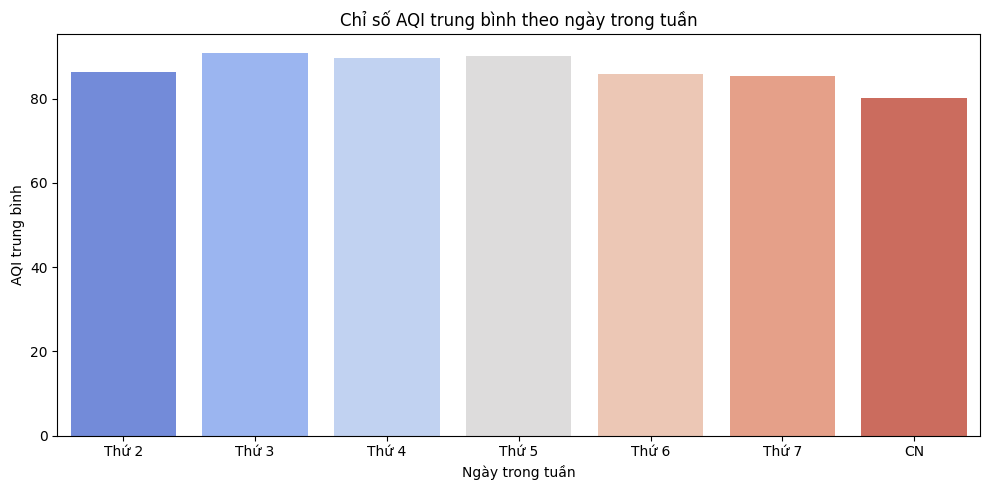

In [ ]:
# Thêm cột thứ trong tuần (0 = Monday, 6 = Sunday)
data["weekday"] = data["timestamp"].dt.dayofweek
weekday_labels = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'CN']

# Trung bình AQI theo thứ trong tuần
weekday_aqi = data.groupby("weekday")["aqi"].mean().reindex(range(7))

# Vẽ biểu đồ
plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_labels, y=weekday_aqi.values, palette="coolwarm")
plt.title("Chỉ số AQI trung bình theo ngày trong tuần")
plt.xlabel("Ngày trong tuần")
plt.ylabel("AQI trung bình")
plt.tight_layout()
plt.show()

/tmp/ipython-input-14-977533321.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_high_aqi, x="city", order=df_high_aqi["city"].value_counts().index, palette="coolwarm")


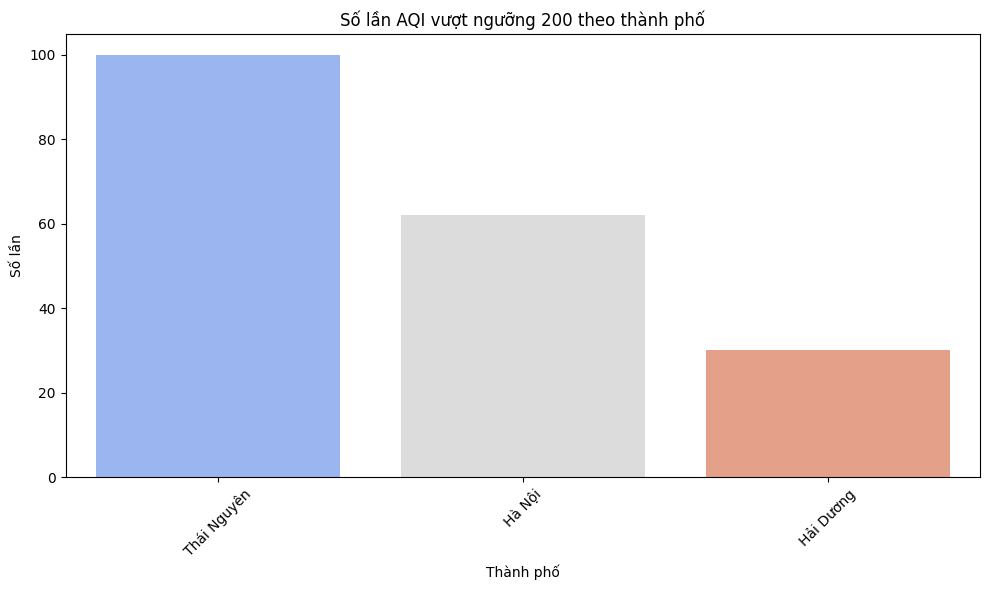

In [ ]:
# Chọn các điểm AQI vượt ngưỡng
df_high_aqi = data[data["aqi"] > 200].copy()
df_high_aqi["hour"] = df_high_aqi["timestamp"].dt.hour

# Biểu đồ số lượng điểm AQI > 200 theo thành phố
plt.figure(figsize=(10, 6))
sns.countplot(data=df_high_aqi, x="city", order=df_high_aqi["city"].value_counts().index, palette="coolwarm")
plt.title("Số lần AQI vượt ngưỡng 200 theo thành phố")
plt.xlabel("Thành phố")
plt.ylabel("Số lần")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

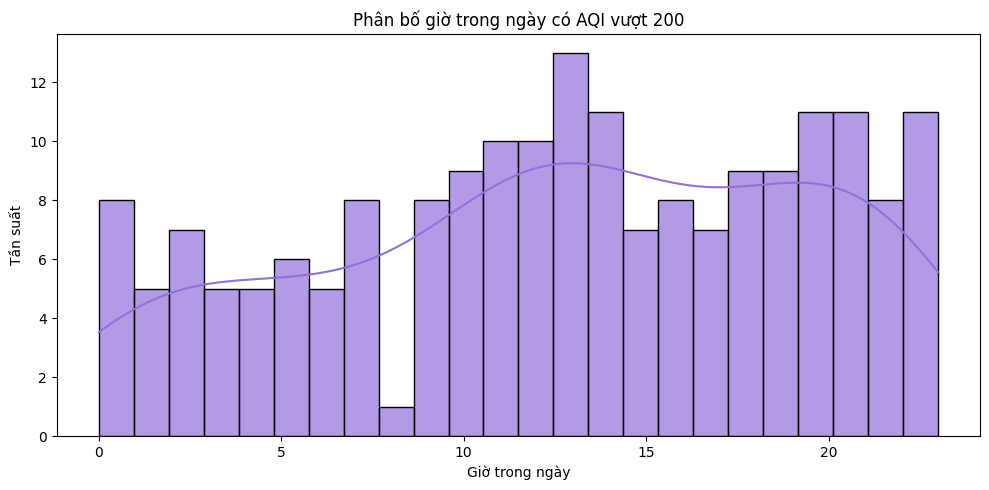

In [ ]:
# Biểu đồ phân bố thời gian (giờ) AQI > 200
plt.figure(figsize=(10, 5))
sns.histplot(
    df_high_aqi["hour"],
    bins=24,
    kde=True,
    color="#9370DB",   # DeepSkyBlue đẹp hơn
    edgecolor="black",
    alpha=0.7          # Tăng độ mờ cho dễ nhìn
)
plt.title("Phân bố giờ trong ngày có AQI vượt 200")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.show()

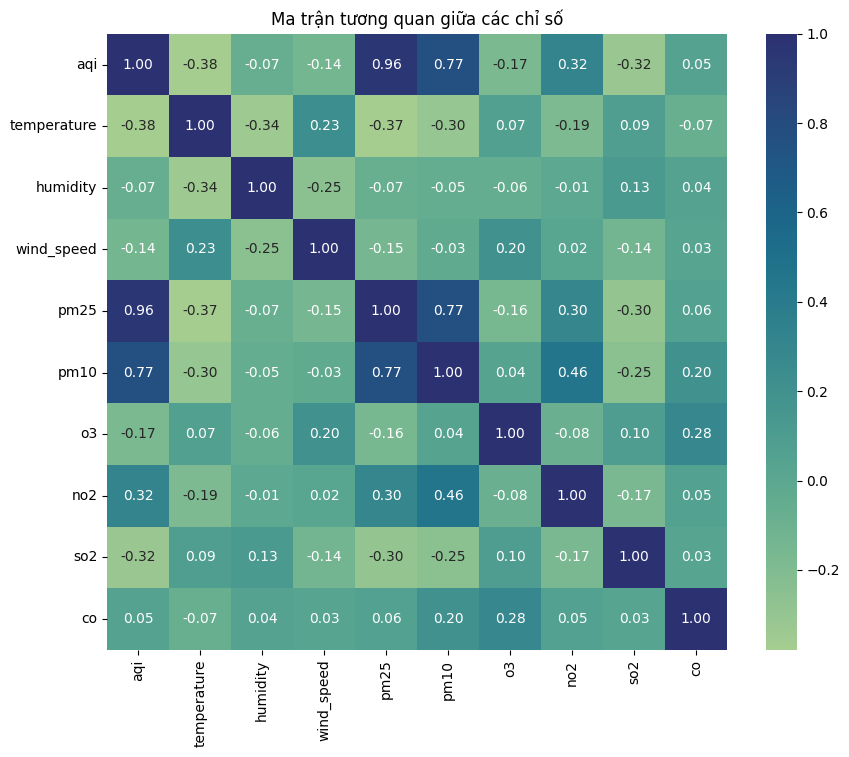

In [ ]:
numeric_cols = ["aqi", "temperature", "humidity", "wind_speed", "pm25", "pm10", "o3", "no2", "so2", "co"]
corr = data[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="crest", fmt=".2f")
plt.title("Ma trận tương quan giữa các chỉ số")
plt.show()